In [6]:
!pip -q install imutils

!rm -rf PersonDetection
!git clone https://github.com/RashadGarayev/PersonDetection.git

!rm -f *.mp4 *.avi *.jpg *.png *.zip

!wget -q -O pedestrian_video_full.avi "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/vtest.avi"
!ffmpeg -y -loglevel error -i pedestrian_video_full.avi -t 15 -vf "scale=640:-2" -vcodec libx264 -pix_fmt yuv420p pedestrian_video_15s.mp4

!wget -q -O lane_video_source.mp4 "https://raw.githubusercontent.com/udacity/CarND-LaneLines-P1/master/test_videos/solidWhiteRight.mp4"
!ffmpeg -y -loglevel error -i lane_video_source.mp4 -t 15 -vf "scale=640:-2" -vcodec libx264 -pix_fmt yuv420p lane_video_15s.mp4

print("DONE")

Cloning into 'PersonDetection'...
remote: Enumerating objects: 6677, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 6677 (delta 3), reused 3 (delta 0), pack-reused 6668 (from 1)
Receiving objects: 100% (6677/6677), 65.69 MiB | 36.44 MiB/s, done.
Resolving deltas: 100% (190/190), done.
DONE


In [7]:
import os
import cv2
import zipfile
import subprocess
import numpy as np
import matplotlib.pyplot as plt

from base64 import b64encode
from IPython.display import display, HTML
from google.colab import files
from imutils.object_detection import non_max_suppression

hog = cv2.HOGDescriptor()
hog.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

print("READY")

READY


In [8]:
def resize_keep_aspect(frame, width=640):
    h, w = frame.shape[:2]
    if w == width:
        return frame
    ratio = width / float(w)
    return cv2.resize(frame, (width, int(h * ratio)))

def convert_to_playable(input_path, output_path):
    if os.path.exists(output_path):
        os.remove(output_path)
    subprocess.run(
        [
            "ffmpeg", "-y", "-loglevel", "error",
            "-i", input_path,
            "-vcodec", "libx264",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
            output_path
        ],
        check=True
    )

def show_bgr_image(path_or_img, title=""):
    if isinstance(path_or_img, str):
        img = cv2.imread(path_or_img)
    else:
        img = path_or_img.copy()
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.title(title)
    plt.show()

def show_video(path, width=720):
    mp4 = open(path, "rb").read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    html = f'<video width="{width}" controls><source src="{data_url}" type="video/mp4"></video>'
    display(HTML(html))

def detect_pedestrians(frame):
    frame = resize_keep_aspect(frame, width=640)
    output = frame.copy()

    parameter_sets = [
        {"winStride": (4, 4), "padding": (16, 16), "scale": 1.03, "hitThreshold": 0.0},
        {"winStride": (4, 4), "padding": (8, 8),  "scale": 1.05, "hitThreshold": 0.0},
        {"winStride": (8, 8), "padding": (16, 16), "scale": 1.05, "hitThreshold": 0.0},
        {"winStride": (4, 4), "padding": (16, 16), "scale": 1.03, "hitThreshold": -0.2},
    ]

    best_boxes = []

    for params in parameter_sets:
        rects, weights = hog.detectMultiScale(
            frame,
            winStride=params["winStride"],
            padding=params["padding"],
            scale=params["scale"],
            hitThreshold=params["hitThreshold"]
        )

        boxes = []

        for (x, y, w, h) in rects:
            aspect_ratio = h / float(w)

            if 35 <= w <= 220 and 70 <= h <= 360 and 1.25 <= aspect_ratio <= 4.5:
                boxes.append([x, y, x + w, y + h])

        if len(boxes) > 0:
            boxes = np.array(boxes)
            picked = non_max_suppression(boxes, probs=None, overlapThresh=0.65)
            best_boxes = [tuple(map(int, box)) for box in picked]
            break

    for (x1, y1, x2, y2) in best_boxes:
        cv2.rectangle(output, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(output, "Pedestrian", (x1, max(25, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    return output, best_boxes, frame

print("FUNCTIONS READY")

FUNCTIONS READY


Saved original_image.jpg
Saved detected_image.jpg
Detected boxes: 2


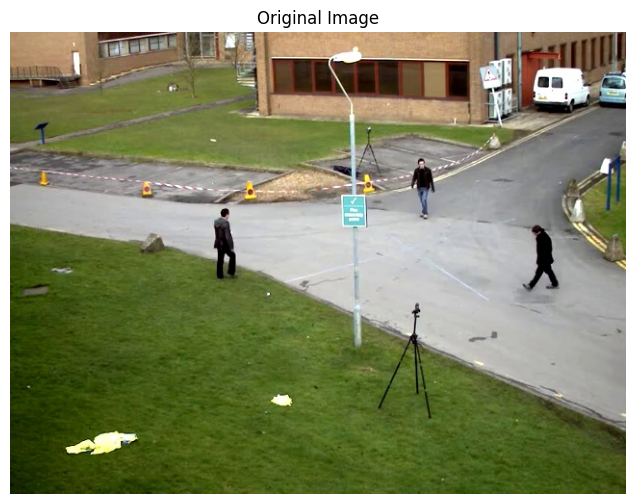

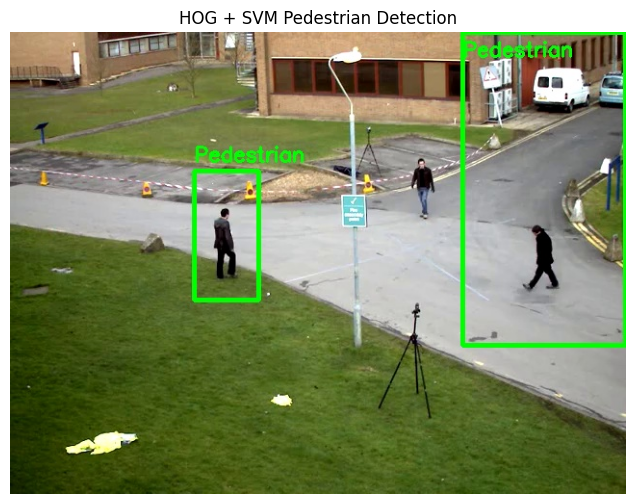

In [9]:
video_path = "pedestrian_video_15s.mp4"

cap = cv2.VideoCapture(video_path)

best_frame = None
best_boxes = []
best_count = -1
frame_number = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    if frame_number % 3 == 0:
        detected_frame, boxes, resized_frame = detect_pedestrians(frame)

        if len(boxes) > best_count:
            best_count = len(boxes)
            best_frame = resized_frame.copy()
            best_boxes = boxes

        if len(boxes) >= 2:
            best_frame = resized_frame.copy()
            best_boxes = boxes
            break

    frame_number += 1

cap.release()

if best_frame is None:
    raise RuntimeError("No frame was found in the video.")

cv2.imwrite("original_image.jpg", best_frame)

detected_image, image_boxes, _ = detect_pedestrians(best_frame)
cv2.imwrite("detected_image.jpg", detected_image)

print("Saved original_image.jpg")
print("Saved detected_image.jpg")
print("Detected boxes:", len(image_boxes))

show_bgr_image("original_image.jpg", "Original Image")
show_bgr_image("detected_image.jpg", "HOG + SVM Pedestrian Detection")

In [10]:
def process_pedestrian_video(input_path, temp_path, output_path):
    cap = cv2.VideoCapture(input_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        fps = 15

    ret, first_frame = cap.read()
    if not ret:
        raise RuntimeError("Could not read pedestrian video.")

    first_frame = resize_keep_aspect(first_frame, width=640)
    h, w = first_frame.shape[:2]

    writer = cv2.VideoWriter(
        temp_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (w, h)
    )

    detected_first, _, _ = detect_pedestrians(first_frame)
    writer.write(detected_first)

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame = resize_keep_aspect(frame, width=640)
        detected_frame, boxes, _ = detect_pedestrians(frame)
        writer.write(detected_frame)

    cap.release()
    writer.release()

    convert_to_playable(temp_path, output_path)

process_pedestrian_video(
    "pedestrian_video_15s.mp4",
    "pedestrian_detection_temp.mp4",
    "pedestrian_detection_video.mp4"
)

print("Saved pedestrian_detection_video.mp4")
show_video("pedestrian_detection_video.mp4")

Saved pedestrian_detection_video.mp4


In [11]:
def region_of_interest(edges):
    h, w = edges.shape
    mask = np.zeros_like(edges)

    polygon = np.array([[
        (int(0.08 * w), h),
        (int(0.43 * w), int(0.60 * h)),
        (int(0.58 * w), int(0.60 * h)),
        (int(0.95 * w), h)
    ]], dtype=np.int32)

    cv2.fillPoly(mask, polygon, 255)
    return cv2.bitwise_and(edges, mask)

def make_lane_line(frame, line_parameters):
    slope, intercept = line_parameters
    h, w = frame.shape[:2]

    y1 = h
    y2 = int(h * 0.62)

    if abs(slope) < 1e-6:
        return None

    x1 = int((y1 - intercept) / slope)
    x2 = int((y2 - intercept) / slope)

    x1 = max(0, min(w - 1, x1))
    x2 = max(0, min(w - 1, x2))

    return np.array([x1, y1, x2, y2])

def average_lane_lines(frame, lines):
    left_fit = []
    right_fit = []

    if lines is None:
        return []

    for line in lines:
        x1, y1, x2, y2 = line.reshape(4)

        if x2 == x1:
            continue

        slope = (y2 - y1) / float(x2 - x1)
        intercept = y1 - slope * x1

        if abs(slope) < 0.35:
            continue

        if slope < 0:
            left_fit.append((slope, intercept))
        else:
            right_fit.append((slope, intercept))

    lane_lines = []

    if len(left_fit) > 0:
        lane_lines.append(make_lane_line(frame, np.average(left_fit, axis=0)))

    if len(right_fit) > 0:
        lane_lines.append(make_lane_line(frame, np.average(right_fit, axis=0)))

    return [line for line in lane_lines if line is not None]

def lane_detection_frame(frame):
    frame = resize_keep_aspect(frame, width=640)

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 50, 150)

    cropped_edges = region_of_interest(edges)

    lines = cv2.HoughLinesP(
        cropped_edges,
        rho=2,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=40,
        maxLineGap=120
    )

    averaged_lines = average_lane_lines(frame, lines)

    line_image = np.zeros_like(frame)

    for line in averaged_lines:
        x1, y1, x2, y2 = line
        cv2.line(line_image, (x1, y1), (x2, y2), (0, 0, 255), 8)

    combined = cv2.addWeighted(frame, 0.8, line_image, 1.0, 1.0)
    return combined

def process_lane_video(input_path, temp_path, output_path):
    cap = cv2.VideoCapture(input_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        fps = 15

    ret, first_frame = cap.read()
    if not ret:
        raise RuntimeError("Could not read lane video.")

    first_frame = resize_keep_aspect(first_frame, width=640)
    h, w = first_frame.shape[:2]

    writer = cv2.VideoWriter(
        temp_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (w, h)
    )

    writer.write(lane_detection_frame(first_frame))

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        lane_frame = lane_detection_frame(frame)
        writer.write(lane_frame)

    cap.release()
    writer.release()

    convert_to_playable(temp_path, output_path)

process_lane_video(
    "lane_video_15s.mp4",
    "lane_detection_temp.mp4",
    "lane_detection_video.mp4"
)

print("Saved lane_detection_video.mp4")
show_video("lane_detection_video.mp4")

Saved lane_detection_video.mp4


Saved optical_flow_tracking_result.mp4
Saved optical_flow_tracking_result.jpg


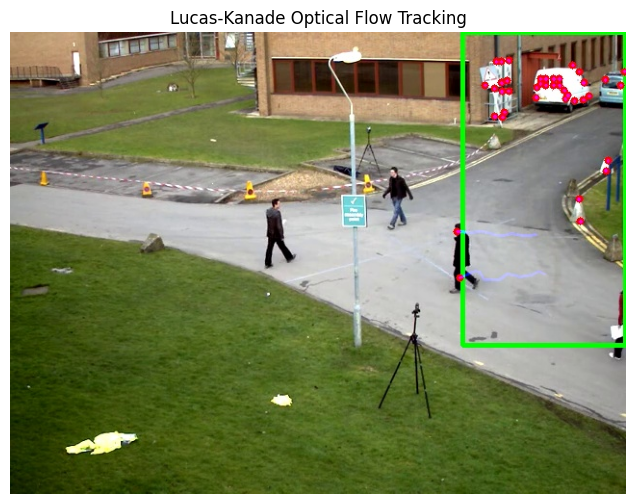

In [12]:
def optical_flow_tracking(input_path, temp_path, output_path, result_image_path):
    cap = cv2.VideoCapture(input_path)

    frames = []

    while len(frames) < 120:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(resize_keep_aspect(frame, width=640))

    cap.release()

    if len(frames) < 12:
        raise RuntimeError("Not enough frames for optical flow.")

    start_index = None
    selected_box = None

    for i, frame in enumerate(frames[:-11]):
        detected_frame, boxes, _ = detect_pedestrians(frame)

        if len(boxes) > 0:
            boxes_sorted = sorted(
                boxes,
                key=lambda b: (b[2] - b[0]) * (b[3] - b[1]),
                reverse=True
            )
            selected_box = boxes_sorted[0]
            start_index = i
            break

    if start_index is None:
        raise RuntimeError("No pedestrian was detected for optical flow.")

    x1, y1, x2, y2 = selected_box

    first_frame = frames[start_index].copy()
    old_gray = cv2.cvtColor(first_frame, cv2.COLOR_BGR2GRAY)

    feature_mask = np.zeros_like(old_gray)
    feature_mask[y1:y2, x1:x2] = 255

    p0 = cv2.goodFeaturesToTrack(
        old_gray,
        mask=feature_mask,
        maxCorners=40,
        qualityLevel=0.01,
        minDistance=5,
        blockSize=7
    )

    if p0 is None:
        raise RuntimeError("No feature points were found inside the pedestrian box.")

    h, w = first_frame.shape[:2]

    writer = cv2.VideoWriter(
        temp_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        5,
        (w, h)
    )

    lk_params = dict(
        winSize=(15, 15),
        maxLevel=2,
        criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)
    )

    track_mask = np.zeros_like(first_frame)
    old_points = p0
    final_frame = first_frame.copy()

    for frame_index in range(start_index, start_index + 11):
        frame = frames[frame_index].copy()
        frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)

        if frame_index == start_index:
            for point in old_points:
                px, py = point.ravel()
                cv2.circle(frame, (int(px), int(py)), 4, (0, 0, 255), -1)

            final_frame = frame.copy()
            writer.write(frame)
            continue

        new_points, status, error = cv2.calcOpticalFlowPyrLK(
            old_gray,
            frame_gray,
            old_points,
            None,
            **lk_params
        )

        if new_points is None:
            break

        good_new = new_points[status == 1]
        good_old = old_points[status == 1]

        for new, old in zip(good_new, good_old):
            a, b = new.ravel()
            c, d = old.ravel()

            cv2.line(track_mask, (int(a), int(b)), (int(c), int(d)), (255, 0, 0), 2)
            cv2.circle(frame, (int(a), int(b)), 4, (0, 0, 255), -1)

        frame_with_tracks = cv2.add(frame, track_mask)
        final_frame = frame_with_tracks.copy()
        writer.write(frame_with_tracks)

        old_gray = frame_gray.copy()
        old_points = good_new.reshape(-1, 1, 2)

        if len(old_points) == 0:
            break

    writer.release()

    cv2.imwrite(result_image_path, final_frame)
    convert_to_playable(temp_path, output_path)

optical_flow_tracking(
    "pedestrian_video_15s.mp4",
    "optical_flow_tracking_temp.mp4",
    "optical_flow_tracking_result.mp4",
    "optical_flow_tracking_result.jpg"
)

print("Saved optical_flow_tracking_result.mp4")
print("Saved optical_flow_tracking_result.jpg")

show_bgr_image("optical_flow_tracking_result.jpg", "Lucas-Kanade Optical Flow Tracking")
show_video("optical_flow_tracking_result.mp4")

In [13]:
files_to_submit = [
    "original_image.jpg",
    "detected_image.jpg",
    "pedestrian_detection_video.mp4",
    "lane_detection_video.mp4",
    "optical_flow_tracking_result.mp4",
    "optical_flow_tracking_result.jpg"
]

zip_name = "assignment_outputs.zip"

with zipfile.ZipFile(zip_name, "w") as zipf:
    for file_name in files_to_submit:
        if os.path.exists(file_name):
            zipf.write(file_name)
            print("Added:", file_name)
        else:
            print("Missing:", file_name)

print("Saved", zip_name)
files.download(zip_name)

Added: original_image.jpg
Added: detected_image.jpg
Added: pedestrian_detection_video.mp4
Added: lane_detection_video.mp4
Added: optical_flow_tracking_result.mp4
Added: optical_flow_tracking_result.jpg
Saved assignment_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>